# Walkthrough: supply chains, matrix powers and strong regularity

This notebook walks through the whole analysis one step at a time, with the
reasoning between the steps. Every number in the paper comes from
`scripts/run_analysis.py`; this notebook recomputes the key ones live, and reads
the slow parts (the threshold sweep with its random benchmarks) from `results/`.

**Two questions.**
1. *How long are US supply chains?* The article's theorem that powers of an
   adjacency matrix count walks, in weighted form, answers this exactly.
2. *How structured is the network?* Turn it into a graph and measure how far it is
   from **strongly regular**, the most uniform kind of graph, against random graphs.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
from IPython.display import Image
from supplygraphs import data, leontief as lf, graphs as gr, analysis as an
pd.set_option("display.width", 120)

## 1. The data: who buys from whom

The US Bureau of Economic Analysis publishes how much of each commodity every
industry buys and makes. From those tables we build the **direct-requirements
matrix** $A$: $a_{ij}$ is the number of dollars of industry $i$'s output used
to make one dollar of industry $j$'s output (see `docs/DATA.md`).

400 industries, numbered in order of BEA code; this ordering is used for every matrix.

In [2]:
A, ind = data.load(2017)
print(A.shape)
ind[["index", "code", "name", "sector"]].head(8)

(400, 400)


,index,code,name,sector
0,1,1111A0,Oilseed farming,"Agriculture, forestry, fishing, and hunting"
1,2,1111B0,Grain farming,"Agriculture, forestry, fishing, and hunting"
2,3,111200,Vegetable and melon farming,"Agriculture, forestry, fishing, and hunting"
3,4,111300,Fruit and tree nut farming,"Agriculture, forestry, fishing, and hunting"
4,5,111400,"Greenhouse, nursery, and floriculture production","Agriculture, forestry, fishing, and hunting"
5,6,111900,Other crop farming,"Agriculture, forestry, fishing, and hunting"
6,7,112120,Dairy cattle and milk production,"Agriculture, forestry, fishing, and hunting"
7,8,1121A0,"Beef cattle ranching and farming, including fe...","Agriculture, forestry, fishing, and hunting"


In [3]:
ind["sector"].value_counts()

sector
Manufacturing                                                        230
Professional and business services                                    24
Educational services, health care, and social assistance              16
Information                                                           15
Finance, insurance, real estate, rental, and leasing                  15
Agriculture, forestry, fishing, and hunting                           13
Construction                                                          12
Arts, entertainment, recreation, accommodation, and food services     12
Other services, except government                                     12
Wholesale trade                                                       11
Government                                                            11
Retail trade                                                           9
Transportation and warehousing                                         9
Mining                                      

Each column of $A$ is one industry's recipe. For example, what does a dollar of
**truck transportation** need directly?

In [4]:
j = ind.index[ind["name"] == "Truck transportation"][0]
pd.Series(A[:, j], index=ind["name"]).sort_values(ascending=False).head(6).round(3)

name
Scenic and sightseeing transportation and support activities    0.069
Petroleum refineries                                            0.050
Truck transportation                                            0.039
Insurance carriers, except direct life                          0.035
Couriers and messengers                                         0.035
Employment services                                             0.020
dtype: float64

## 2. Supply chains are weighted walks

Think of $A$ as a weighted directed graph: an arc $i \to j$ of weight $a_{ij}$.
The article's walk-counting theorem, with weights, says

$$(A^k)_{ij} = \sum_{\text{walks } i=v_0\to\cdots\to v_k=j} a_{v_0v_1}\cdots a_{v_{k-1}v_k},$$

the requirement of $j$ for $i$'s output through supply chains of exactly $k$ steps.
Check it by brute force on a 4-industry piece of $A$:

In [5]:
import itertools
S = A[:4, :4]; k = 3
brute = np.zeros((4, 4))
for i in range(4):
    for jj in range(4):
        for mid in itertools.product(range(4), repeat=k - 1):
            path = (i, *mid, jj)
            brute[i, jj] += np.prod([S[path[t], path[t + 1]] for t in range(k)])
np.allclose(np.linalg.matrix_power(S, k), brute)

True

Summing over all lengths gives the **Leontief inverse** $L = (I-A)^{-1} = I + A + A^2 + \cdots$,
valid when the spectral radius $\rho(A) < 1$.

The usual way to guarantee that, *every column sum below 1*, **fails** here for
one industry:

In [6]:
colsum = pd.Series(A.sum(axis=0), index=ind["name"]).sort_values(ascending=False)
colsum.head(3).round(3)

name
State and local government passenger transit    1.595
Funds, trusts, and other financial vehicles     0.955
Other federal government enterprises            0.923
dtype: float64

State and local government passenger transit has negative value added in the
tables, so its intermediate purchases exceed its output. We compute $\rho(A)$
directly instead, and check that the series converges:

In [7]:
rho = lf.spectral_radius(A)
L = lf.leontief_inverse(A)
print(f"rho(A) = {rho:.4f}")
for k in (5, 10, 20):
    print(k, "terms: max error", f"{np.abs(lf.neumann_partial_sum(A, k) - L).max():.1e}")

rho(A) = 0.4886
5 terms: max error 7.2e-03
10 terms: max error 1.9e-04


20 terms: max error 1.5e-07


## 3. How long are supply chains?

$s_k$ = share of all requirements carried by chains of exactly $k$ steps.
The average length $\sum_k k s_k$ has the closed form
$\mathbf 1^\top (L-I)L\mathbf 1 / \mathbf 1^\top (L-I)\mathbf 1$ (proved in the paper).

In [8]:
s = lf.walk_shares(A, 8)
print("shares (%):", np.round(100 * s, 1))
print("ratios s_{k+1}/s_k:", np.round(s[1:] / s[:-1], 3), " vs rho =", round(rho, 3))
print("average chain length:", round(lf.average_chain_length(A), 2), "steps")

shares (%): [48.3 25.5 13.1  6.6  3.3  1.6  0.8  0.4]
ratios s_{k+1}/s_k: [0.528 0.514 0.505 0.499 0.494 0.492 0.491]  vs rho = 0.489
average chain length: 2.04 steps


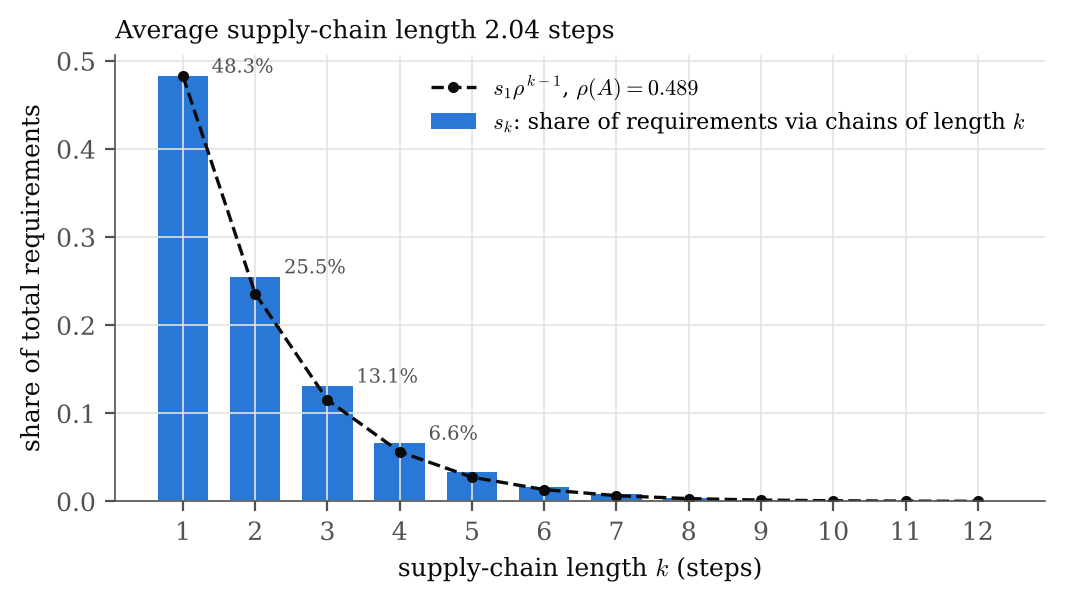

In [9]:
Image(filename=str(ROOT / "paper/figures/fig-walks.png"))

Each extra step carries about half as much as the step before, at a rate close
to $\rho(A)$. That is the Perron–Frobenius theorem at work: for a non-negative
matrix the spectral radius is itself an eigenvalue, and it sets how fast $A^k$ decays.

**Output multipliers** (column sums of $L$): total output needed across the
economy for \$1 of an industry's final product.

In [10]:
m = pd.Series(lf.output_multipliers(A), index=ind["name"]).sort_values(ascending=False)
m.head(6).round(2)

name
State and local government passenger transit       4.26
Poultry and egg production                         3.22
Cheese manufacturing                               3.19
Fats and oils refining and blending                3.13
Poultry processing                                 3.13
Copper rolling, drawing, extruding and alloying    3.11
dtype: float64

## 4. From requirements to a graph

Join $i$ and $j$ when one buys at least $\theta$ dollars from the other per
dollar of its output: $\max(a_{ij}, a_{ji}) \ge \theta$. We pick $\theta^*$ so
that the graph has exactly the density of the **Hamming graph $H(2,20)$**, a
strongly regular graph on exactly 400 vertices with parameters (400, 38, 18, 2).

In [11]:
W = gr.link_weights(A)
theta_star = an.theta_for_density(W, an.TARGET_DENSITY)
G = gr.threshold_adjacency(W, theta_star)
print(f"theta* = {theta_star:.4f} dollars per dollar ({100 * theta_star:.2f} cents)")
pd.Series(gr.structure_profile(G)).round(3)

theta* = 0.0047 dollars per dollar (0.47 cents)


m                         7600.000
density                      0.095
mean_degree                 38.000
sd_degree                   37.584
max_degree                 323.000
n_isolated                   2.000
n_components                 3.000
largest_component          398.000
clique_number               14.000
lambda1                     62.219
lambda2                     29.581
spectral_gap                32.638
lambda_min                 -28.232
n_distinct_eigenvalues     399.000
dtype: float64

Mean degree 38, but very unequal degrees. Who are the hubs?

In [12]:
deg = pd.Series(G.sum(axis=1), index=ind["name"]).sort_values(ascending=False)
deg.head(8)

name
Management of companies and enterprises                      323
Truck transportation                                         289
Other real estate                                            279
Electric power generation, transmission, and distribution    239
Other durable goods merchant wholesalers                     217
Monetary authorities and depository credit intermediation    202
Other nondurable goods merchant wholesalers                  178
Employment services                                          170
dtype: int64

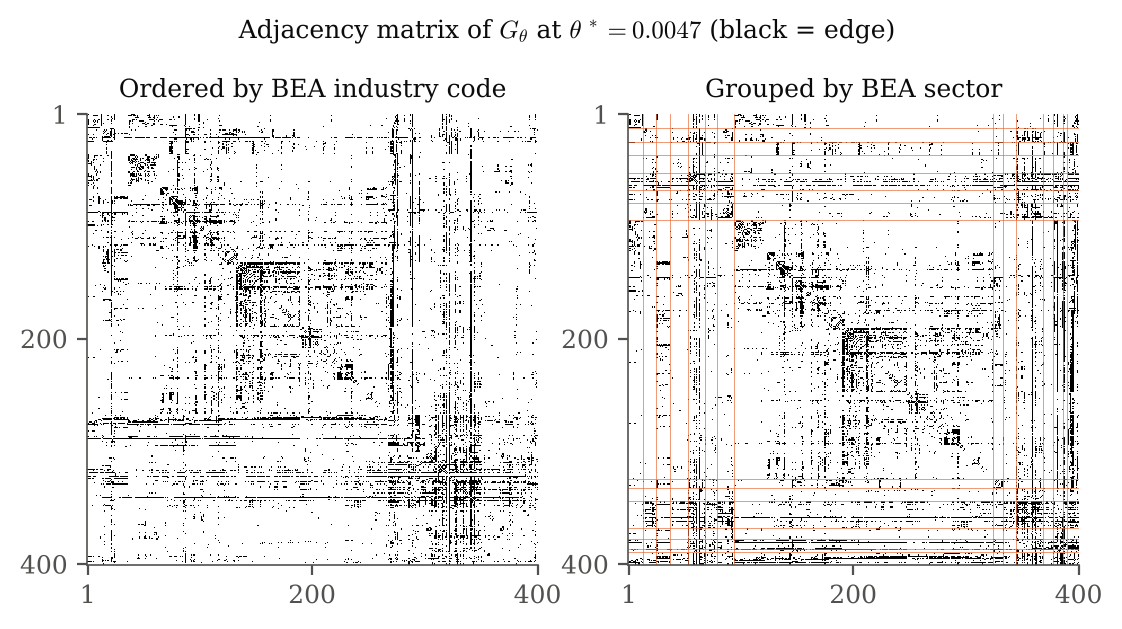

In [13]:
Image(filename=str(ROOT / "paper/figures/fig-adjacency.png"))

## 5. The instrument: common neighbours

$(A_\theta^2)_{uv}$ counts common neighbours. In a strongly regular graph it is
$\lambda$ on every edge and $\mu$ on every non-edge. Here these are two
*distributions*, and the paper proves exactly how far they are from constant:

$$\min_{k,\lambda,\mu}\lVert A^2-kI-\lambda A-\mu\bar A\rVert_F^2
 = n\,\mathrm{Var}(\mathcal D) + 2m\,\mathrm{Var}(\mathcal L) + 2\bar m\,\mathrm{Var}(\mathcal M).$$

In [14]:
prof = gr.regularity_profile(G)
{k: round(v, 3) for k, v in prof.items()}

{'n': 400,
 'm': 7600,
 'm_bar': 72200,
 'k_fit': 38.0,
 'lambda_fit': 17.171,
 'mu_fit': 6.0,
 'gap': 11.171,
 'sd_lambda': 15.218,
 'sd_mu': 4.841,
 'term_degree': 565012.0,
 'term_edge': 3519999.208,
 'term_nonedge': 3383650.0,
 'residual_sq': 7468661.208,
 'delta': 0.649,
 'frac_degree': 0.076,
 'frac_edge': 0.471,
 'frac_nonedge': 0.453}

In [15]:
at_means = gr.residual_norm_sq(G, prof["k_fit"], prof["lambda_fit"], prof["mu_fit"])
print("residual at the means:", at_means, " decomposition:", prof["residual_sq"])
print("moving lambda by 1 makes it worse:",
      gr.residual_norm_sq(G, prof["k_fit"], prof["lambda_fit"] + 1, prof["mu_fit"]) > at_means)

residual at the means: 7468661.2079085875  decomposition: 7468661.2079085875


moving lambda by 1 makes it worse: True


## 6. The benchmarks

In [16]:
rng = np.random.default_rng(0)
H = gr.hamming_graph(2, 20)
rows = {"H(2,20)": gr.regularity_profile(H),
        "Erdos-Renyi": gr.regularity_profile(gr.erdos_renyi(400, G.sum() / (400 * 399), rng)),
        "same degrees": gr.regularity_profile(gr.degree_preserving(G, rng, 5)),
        "industry network": prof}
pd.DataFrame(rows).T[["k_fit", "lambda_fit", "mu_fit", "gap", "delta",
                      "frac_degree", "frac_edge", "frac_nonedge"]].round(3)

,k_fit,lambda_fit,mu_fit,gap,delta,frac_degree,frac_edge,frac_nonedge
"H(2,20)",38.00,18.000,2.000,16.000,0.000,NaN,NaN,NaN
Erdos-Renyi,38.29,3.660,3.658,0.001,0.420,0.022,0.096,0.882
same degrees,38.00,15.589,6.167,9.422,0.661,0.074,0.502,0.424
industry network,38.00,17.171,6.000,11.171,0.649,0.076,0.471,0.453


**Reading the table.** Industries that trade directly share far more trading
partners than industries that do not ($\bar\lambda - \bar\mu \approx 11$).
A random graph gives about 0, and a rewiring that keeps every degree gives about 9.5,
so the hubs explain most but not all of it. The strongly regular graph gives 16.
The network is far from strongly regular ($\delta \approx 0.65$), and the decomposition
says why: shared-partner counts vary from pair to pair. Unequal degrees contribute only 8%.

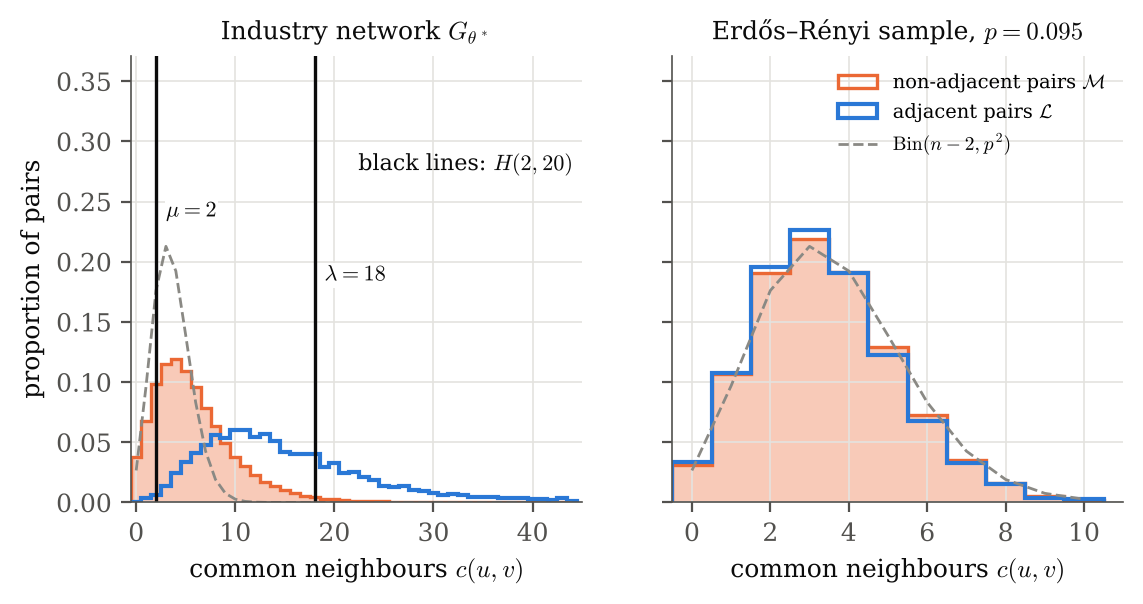

In [17]:
Image(filename=str(ROOT / "paper/figures/fig-common-neighbours.png"))

## 7. Is $\theta^*$ special? The full sweep

49 thresholds from $10^{-4}$ to $10^{-1}$, with 200 random graphs and 20
rewirings per threshold. This takes several minutes, so it is read from
`results/sweep_2017.csv`.

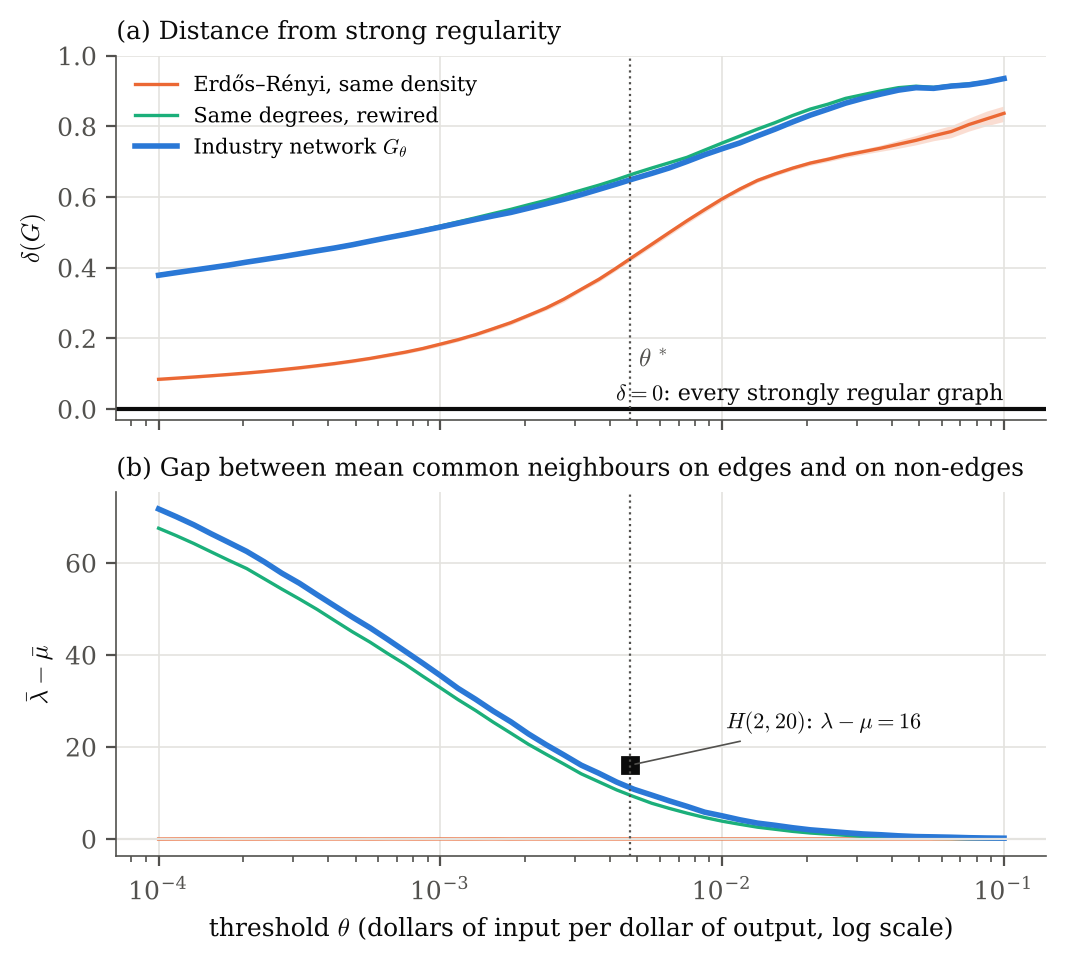

In [18]:
Image(filename=str(ROOT / "paper/figures/fig-delta-sweep.png"))

In [19]:
summary = json.loads((ROOT / "results/summary.json").read_text())
summary["ranges"]

{'gap_above_dp_band': [[0.0001, 0.1]],
 'gap_above_er_band': [[0.0001, 0.1]],
 'delta_above_er_band': [[0.0001, 0.1]],
 'delta_below_dp_band': [[0.0001, 0.08659643]]}

## 8. Spectra

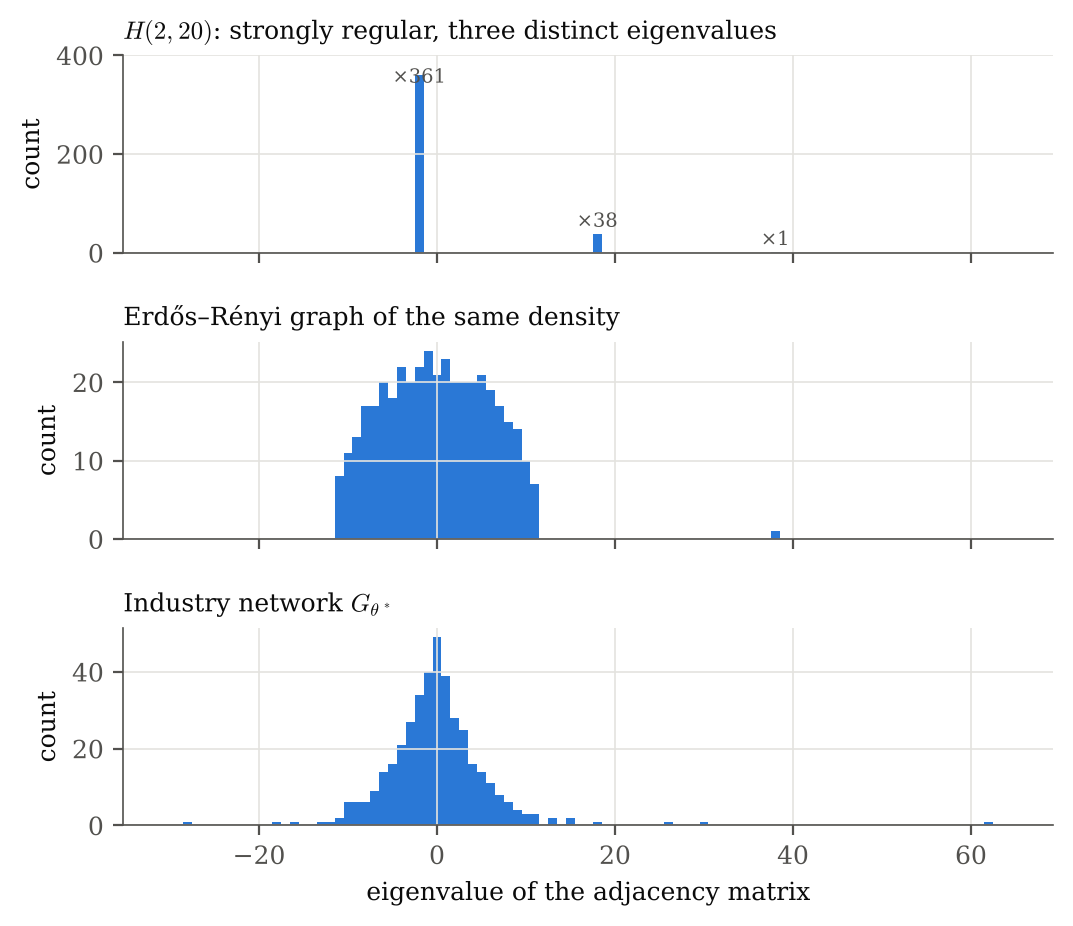

In [20]:
Image(filename=str(ROOT / "paper/figures/fig-spectra.png"))

## 9. Does it hold up over time?

2012 at the same 400 industries, and every year 2012–2023 at 71 industries.

In [21]:
years = pd.read_csv(ROOT / "results/years_summary.csv")
years[["year", "rho", "apl", "gap", "dp_gap_hi", "delta", "er_delta_hi", "dp_delta_lo"]].round(3)

,year,rho,apl,gap,dp_gap_hi,delta,er_delta_hi,dp_delta_lo
0,2012,0.506,2.017,1.470,1.316,0.701,0.661,0.712
1,2013,0.508,2.024,1.441,1.315,0.701,0.667,0.712
2,2014,0.506,2.025,1.484,1.356,0.705,0.665,0.714
3,2015,0.489,1.954,1.676,1.393,0.708,0.664,0.718
4,2016,0.483,1.934,1.651,1.245,0.700,0.659,0.708
5,2017,0.489,1.953,1.655,1.475,0.708,0.668,0.715
6,2018,0.494,1.970,1.620,1.491,0.704,0.661,0.714
7,2019,0.485,1.942,1.697,1.529,0.714,0.665,0.719
8,2020,0.471,1.894,1.827,1.560,0.705,0.668,0.718
9,2021,0.491,1.956,1.758,1.408,0.698,0.667,0.709


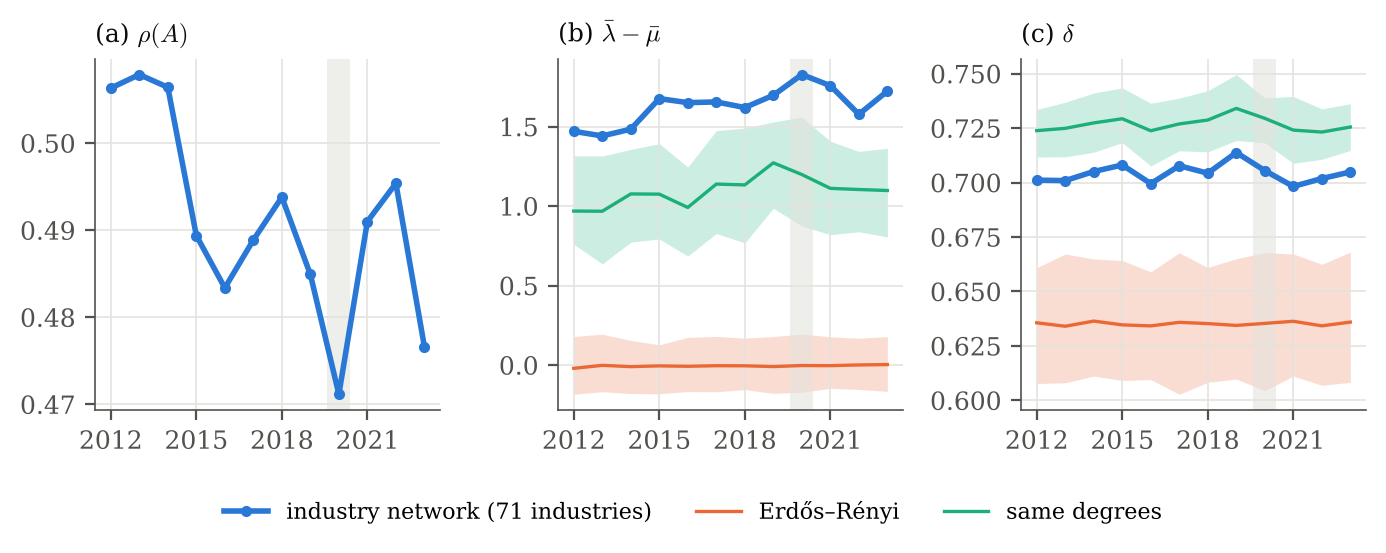

In [22]:
Image(filename=str(ROOT / "paper/figures/fig-years.png"))

## What this does and does not show

* It shows, for **the US input–output tables, 2012–2023**, how long supply chains
  are, which industries are hubs, and where the network sits between the two exact
  extremes of perfect uniformity and pure randomness.
* It does not describe individual firms (an industry aggregates many), other
  countries, or how chains respond to shocks. See the Limitations section of the paper.